
STEP 4 RECONSTRUCTION: 1 arcmin noise
Observations loaded: 166

Coarse period search...
Best coarse period: 691.0 days
Fine period search...
Best inferred period: 689.25 days

Top candidate periods:
 period_days  number_of_bundles  median_ray_rms_AU  mean_ray_rms_AU  median_reconstructed_radius_AU
      689.25                 26           0.012352         0.013010                        1.538721
      689.50                 26           0.012352         0.012914                        1.542253
      690.50                 26           0.012352         0.012914                        1.542253
      690.75                 26           0.012352         0.013010                        1.538721
      691.00                 37           0.015112         0.057760                        1.567610
      686.00                 31           0.016191         0.015771                        1.481076
      689.00                 41           0.016649         0.031129                        1.573274


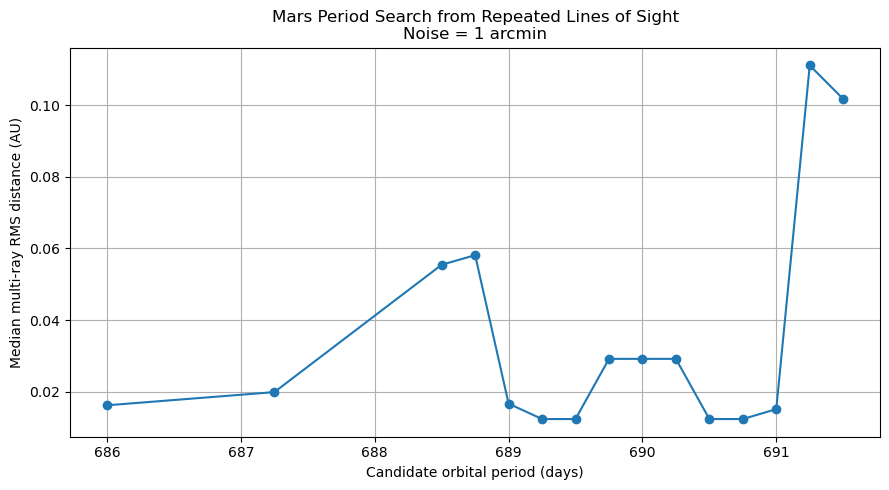


--------------------------------------------
FINAL RESULTS
--------------------------------------------
Inferred period: 689.25 days
Reconstructed positions: 26
Minimum heliocentric radius: 1.4268026517135326 AU
Median heliocentric radius: 1.5387211107753278 AU
Maximum heliocentric radius: 1.6071891253259258 AU
Median multi-ray RMS error: 0.012351770866159344 AU
Median |z|: 0.00013354152335943705 AU

Saved: mars_reconstructed_1arcmin.csv

STEP 4 RECONSTRUCTION: 2 arcmin noise
Observations loaded: 166

Coarse period search...
Best coarse period: 691.0 days
Fine period search...
Best inferred period: 689.25 days

Top candidate periods:
 period_days  number_of_bundles  median_ray_rms_AU  mean_ray_rms_AU  median_reconstructed_radius_AU
      689.25                 26           0.012361         0.013026                        1.538039
      689.50                 26           0.012361         0.012928                        1.542306
      690.50                 26           0.012361       

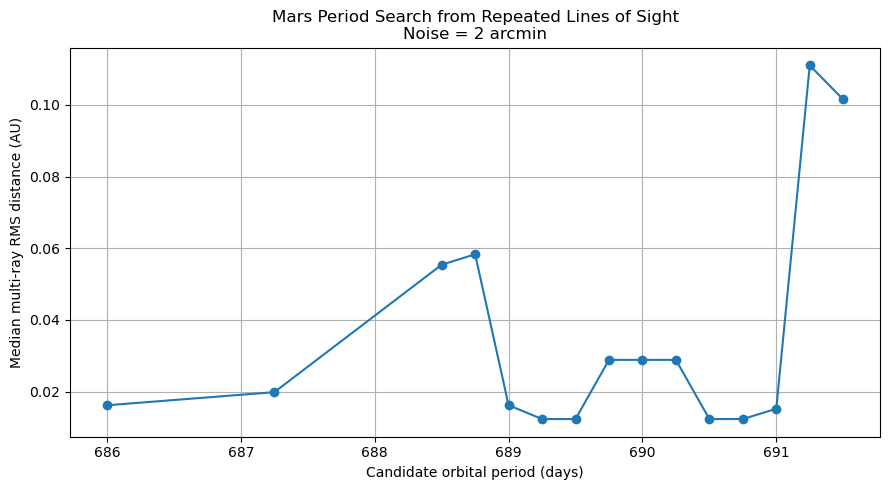


--------------------------------------------
FINAL RESULTS
--------------------------------------------
Inferred period: 689.25 days
Reconstructed positions: 26
Minimum heliocentric radius: 1.4262215519828285 AU
Median heliocentric radius: 1.5380385013290931 AU
Maximum heliocentric radius: 1.6071452005219817 AU
Median multi-ray RMS error: 0.01236090618853795 AU
Median |z|: 0.00026699105790981405 AU

Saved: mars_reconstructed_2arcmin.csv

STEP 4 RECONSTRUCTION: 5 arcmin noise
Observations loaded: 166

Coarse period search...
Best coarse period: 691.0 days
Fine period search...
Best inferred period: 689.25 days

Top candidate periods:
 period_days  number_of_bundles  median_ray_rms_AU  mean_ray_rms_AU  median_reconstructed_radius_AU
      689.25                 26           0.012421         0.013107                        1.535887
      689.50                 26           0.012421         0.013003                        1.542448
      690.50                 26           0.012421        

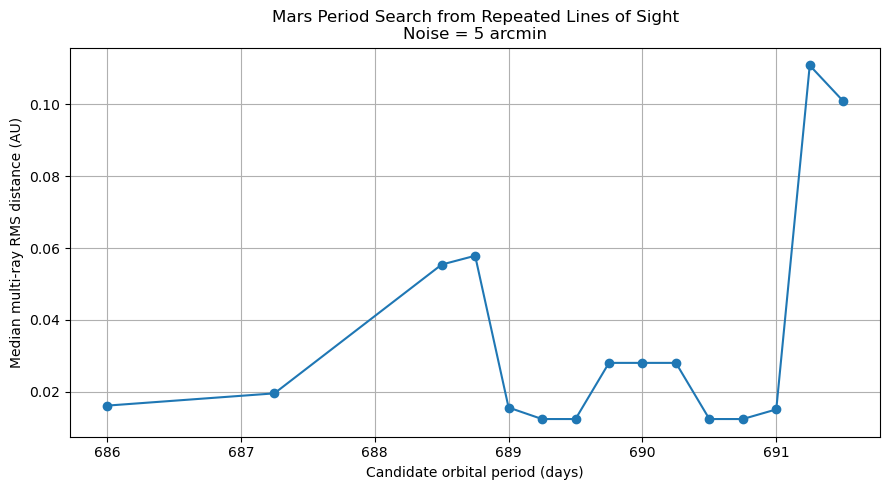


--------------------------------------------
FINAL RESULTS
--------------------------------------------
Inferred period: 689.25 days
Reconstructed positions: 26
Minimum heliocentric radius: 1.4244706616104854 AU
Median heliocentric radius: 1.5358873038249268 AU
Maximum heliocentric radius: 1.6070109252384879 AU
Median multi-ray RMS error: 0.012421087978158211 AU
Median |z|: 0.0006673744289780062 AU

Saved: mars_reconstructed_5arcmin.csv


In [1]:
"""
reconstruct_mars_step4.py

Homework 1.1 - Corrected Step 4

Reconstruct approximate heliocentric positions of Mars
using ONLY:

    1. the noisy RA/Dec observation tables,
    2. Earth's known orbit,
    3. Uraniborg's location,
    4. Earth's rotation.

NO hidden Mars orbital parameters are used.

Main idea
---------
Each observation gives a ray

    r = observer_position + rho * line_of_sight

but rho is unknown.

If Mars returns to approximately the same orbital phase
after some period P, observations separated by

    P, 2P, 3P, ...

should produce several rays passing near the SAME
heliocentric Mars position.

We search for the period that makes groups of 3 or more
rays converge most consistently.
"""

import math
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. CONSTANTS
# ============================================================

AU_KM = 149_597_870.7

R_EARTH_AU = 6378.137 / AU_KM

# Earth's axial tilt
OBLIQUITY = math.radians(
    23.43928
)

# Uraniborg coordinates:
# 55 deg 54' 28" N
# 12 deg 41' 48" E

LAT = math.radians(
    55
    + 54 / 60
    + 28 / 3600
)

LON = math.radians(
    12
    + 41 / 60
    + 48 / 3600
)

# Solar gravitational parameter
# AU^3 / day^2

MU_SUN = (
    4
    * math.pi**2
    / (365.256363004**2)
)


# ============================================================
# 2. KNOWN EARTH ORBIT
# ============================================================
#
# These are Earth parameters only.
#
# There are deliberately NO Mars parameters in this file.
# ============================================================

EARTH = {
    "a": 1.00000011,
    "e": 0.01671022,
    "M0": math.radians(
        357.51716
    ),
    "varpi": math.radians(
        102.93735
    ),
}


# ============================================================
# 3. PERIOD SEARCH SETTINGS
# ============================================================
#
# We DO NOT give the true Mars period to the algorithm.
#
# Instead, search a broad year-scale interval.
#
# You can widen this further if desired.
# ============================================================

PERIOD_MIN = 500.0
PERIOD_MAX = 900.0

COARSE_STEP = 1.0
FINE_STEP = 0.25

# Observations separated by k*P are accepted when they are
# this close to exact repetition.
PHASE_TOLERANCE_DAYS = 2.0

# Need at least 3 different rays to reconstruct a point.
MIN_RAYS = 3

# Require enough independent repeated-phase groups before
# trusting a candidate period.
MIN_BUNDLES = 20

# Limit how many orbital repetitions we use.
MAX_CYCLES = 8

# Important:
# Observers must actually be separated in heliocentric space.
#
# This prevents the previous false reconstruction at ~1 AU
# caused by Earth returning near the same position.
MIN_OBSERVER_BASELINE_AU = 0.30


# ============================================================
# 4. TIME
# ============================================================

J2000 = datetime(
    2000,
    1,
    1,
    12,
    tzinfo=timezone.utc
)


def days_from_j2000(dt):

    return (
        dt - J2000
    ).total_seconds() / 86400.0


# ============================================================
# 5. SOLVE KEPLER'S EQUATION FOR EARTH
# ============================================================

def solve_kepler(
    M,
    e,
    tol=1e-13,
    max_iter=100
):

    # Keep angle in a numerically convenient range.
    M = (
        (M + math.pi)
        % (2 * math.pi)
    ) - math.pi

    E = M

    for _ in range(max_iter):

        f = (
            E
            - e * math.sin(E)
            - M
        )

        df = (
            1
            - e * math.cos(E)
        )

        correction = f / df

        E -= correction

        if abs(correction) < tol:
            return E

    raise RuntimeError(
        "Kepler solver failed."
    )


# ============================================================
# 6. ROTATION ABOUT Z
# ============================================================

def rotate_z(
    vector,
    angle
):

    c = math.cos(angle)
    s = math.sin(angle)

    R = np.array([
        [c, -s, 0.0],
        [s,  c, 0.0],
        [0.0, 0.0, 1.0]
    ])

    return R @ vector


# ============================================================
# 7. EARTH HELIOCENTRIC POSITION
# ============================================================

def earth_position(dt):

    t = days_from_j2000(dt)

    a = EARTH["a"]
    e = EARTH["e"]

    # Mean angular speed
    n = math.sqrt(
        MU_SUN / a**3
    )

    # Mean anomaly
    M = (
        EARTH["M0"]
        + n * t
    )

    E = solve_kepler(
        M,
        e
    )

    # Earth position in its orbital plane
    x = a * (
        math.cos(E)
        - e
    )

    y = (
        a
        * math.sqrt(
            1 - e**2
        )
        * math.sin(E)
    )

    r = np.array([
        x,
        y,
        0.0
    ])

    return rotate_z(
        r,
        EARTH["varpi"]
    )


# ============================================================
# 8. EARTH ROTATION
# ============================================================

def gmst(dt):
    """
    Approximate Greenwich Mean Sidereal Time.
    """

    D = days_from_j2000(dt)

    theta_deg = (
        280.46061837
        + 360.98564736629 * D
    ) % 360.0

    return math.radians(
        theta_deg
    )


# ============================================================
# 9. EQUATORIAL -> ECLIPTIC COORDINATES
# ============================================================

def equatorial_to_ecliptic(v):

    x, y, z = v

    c = math.cos(
        OBLIQUITY
    )

    s = math.sin(
        OBLIQUITY
    )

    return np.array([
        x,
        c*y + s*z,
        -s*y + c*z
    ])


# ============================================================
# 10. URANIBORG POSITION RELATIVE TO EARTH
# ============================================================

def site_position_ecliptic(dt):

    local_angle = (
        gmst(dt)
        + LON
    )

    # Uraniborg "up" direction in equatorial coordinates
    up_equatorial = np.array([
        math.cos(LAT)
        * math.cos(local_angle),

        math.cos(LAT)
        * math.sin(local_angle),

        math.sin(LAT)
    ])

    site_equatorial = (
        R_EARTH_AU
        * up_equatorial
    )

    return equatorial_to_ecliptic(
        site_equatorial
    )


# ============================================================
# 11. HELIOCENTRIC POSITION OF THE OBSERVER
# ============================================================

def observer_position(dt):

    return (
        earth_position(dt)
        +
        site_position_ecliptic(dt)
    )


# ============================================================
# 12. RA/DEC -> UNIT LINE-OF-SIGHT VECTOR
# ============================================================

def radec_to_ecliptic_unit(
    ra_deg,
    dec_deg
):

    ra = math.radians(
        ra_deg
    )

    dec = math.radians(
        dec_deg
    )

    # RA / Dec live in equatorial coordinates.
    u_equatorial = np.array([
        math.cos(dec)
        * math.cos(ra),

        math.cos(dec)
        * math.sin(ra),

        math.sin(dec)
    ])

    # Put them into the same ecliptic coordinate system
    # used by Earth's heliocentric orbit.
    u_ecliptic = (
        equatorial_to_ecliptic(
            u_equatorial
        )
    )

    return (
        u_ecliptic
        / np.linalg.norm(
            u_ecliptic
        )
    )


# ============================================================
# 13. READ OBSERVATION TABLE
# ============================================================

def load_observations(filename):

    df = pd.read_csv(
        filename
    )

    observations = []

    for _, row in df.iterrows():

        # Avoid pandas historical datetime warnings.
        dt = datetime.fromisoformat(
            row["datetime_utc"]
        )

        p = observer_position(
            dt
        )

        u = (
            radec_to_ecliptic_unit(
                row["ra_deg"],
                row["dec_deg"]
            )
        )

        observations.append({
            "datetime": dt,
            "observer": p,
            "direction": u
        })

    return observations


# ============================================================
# 14. FIT ONE COMMON POINT TO MANY RAYS
# ============================================================

def fit_point_to_rays(
    observer_positions,
    directions
):
    """
    Given several rays

        p_i + rho_i u_i,

    find the point x minimizing the sum of squared
    perpendicular distances to all rays.

    For one ray, perpendicular displacement is

        (I - u u^T)(x - p).

    Therefore we minimize

        sum ||(I-u_i u_i^T)(x-p_i)||^2.

    The least-squares normal equation is

        A x = b,

    with

        A = sum(I-u_i u_i^T)

        b = sum(I-u_i u_i^T)p_i.
    """

    A = np.zeros(
        (3, 3)
    )

    b = np.zeros(
        3
    )

    I = np.eye(
        3
    )

    for p, u in zip(
        observer_positions,
        directions
    ):

        projection = (
            I
            -
            np.outer(u, u)
        )

        A += projection

        b += projection @ p

    # Poor geometry -> unreliable reconstruction.
    if np.linalg.cond(A) > 1e10:
        return None

    x = np.linalg.solve(
        A,
        b
    )

    distances = []
    ranges = []

    for p, u in zip(
        observer_positions,
        directions
    ):

        projection = (
            I
            -
            np.outer(u, u)
        )

        perpendicular = (
            projection
            @ (x - p)
        )

        distance = np.linalg.norm(
            perpendicular
        )

        # Distance along the ray.
        rho = np.dot(
            x - p,
            u
        )

        distances.append(
            distance
        )

        ranges.append(
            rho
        )

    distances = np.array(
        distances
    )

    ranges = np.array(
        ranges
    )

    rms_distance = math.sqrt(
        np.mean(
            distances**2
        )
    )

    return (
        x,
        rms_distance,
        ranges
    )


# ============================================================
# 15. BUILD REPEATED-PHASE RAY GROUPS
# ============================================================

def build_bundles_for_period(
    observations,
    candidate_period
):
    """
    For each observation, search for later observations
    separated by approximately

        k * candidate_period,

    where k = 1, 2, 3, ...

    Those observations should see Mars at approximately
    the same heliocentric orbital phase if the candidate
    period is correct.
    """

    first_time = (
        observations[0]["datetime"]
    )

    times = np.array([
        (
            obs["datetime"]
            -
            first_time
        ).total_seconds()
        / 86400.0

        for obs in observations
    ])

    unique_bundles = {}

    N = len(
        observations
    )

    for i in range(N):

        indices = [
            i
        ]

        for j in range(
            i + 1,
            N
        ):

            delta_t = (
                times[j]
                -
                times[i]
            )

            # Number of candidate Mars periods between
            # these observations.
            k = int(
                round(
                    delta_t
                    / candidate_period
                )
            )

            if k < 1:
                continue

            if k > MAX_CYCLES:
                continue

            phase_error = abs(
                delta_t
                -
                k * candidate_period
            )

            if (
                phase_error
                <= PHASE_TOLERANCE_DAYS
            ):

                indices.append(
                    j
                )

        # A pair alone is not enough:
        # use 3 or more lines of sight.
        if len(indices) < MIN_RAYS:
            continue

        # Avoid adding exactly the same group twice.
        key = tuple(
            indices
        )

        if key in unique_bundles:
            continue

        observer_positions = [
            observations[j]["observer"]
            for j in indices
        ]

        directions = [
            observations[j]["direction"]
            for j in indices
        ]

        # ----------------------------------------------------
        # IMPORTANT FIX FOR THE OLD ERROR
        # ----------------------------------------------------
        #
        # Make sure Earth/Uraniborg occupied substantially
        # different heliocentric positions.
        #
        # If observer positions are almost identical,
        # triangulation cannot determine distance.
        # ----------------------------------------------------

        maximum_baseline = 0.0

        for a in range(
            len(observer_positions)
        ):

            for b in range(
                a + 1,
                len(observer_positions)
            ):

                baseline = np.linalg.norm(
                    observer_positions[a]
                    -
                    observer_positions[b]
                )

                maximum_baseline = max(
                    maximum_baseline,
                    baseline
                )

        if (
            maximum_baseline
            < MIN_OBSERVER_BASELINE_AU
        ):
            continue

        fitted = fit_point_to_rays(
            observer_positions,
            directions
        )

        if fitted is None:
            continue

        (
            point,
            rms_distance,
            ranges
        ) = fitted

        # Mars must lie in FRONT of the observers,
        # rather than behind their measured directions.
        if not np.all(
            ranges > 0
        ):
            continue

        unique_bundles[key] = {
            "indices":
                indices,

            "point":
                point,

            "rms_distance":
                rms_distance,

            "ranges":
                ranges,

            "max_baseline":
                maximum_baseline
        }

    return unique_bundles


# ============================================================
# 16. SCORE A CANDIDATE PERIOD
# ============================================================

def score_period(
    observations,
    candidate_period
):

    bundles = build_bundles_for_period(
        observations,
        candidate_period
    )

    number_of_bundles = len(
        bundles
    )

    if (
        number_of_bundles
        < MIN_BUNDLES
    ):
        return None

    errors = np.array([
        bundle["rms_distance"]

        for bundle
        in bundles.values()
    ])

    radii = np.array([
        np.linalg.norm(
            bundle["point"]
        )

        for bundle
        in bundles.values()
    ])

    return {
        "period_days":
            candidate_period,

        "number_of_bundles":
            number_of_bundles,

        # This is our main score.
        "median_ray_rms_AU":
            np.median(
                errors
            ),

        "mean_ray_rms_AU":
            np.mean(
                errors
            ),

        # Diagnostic only.
        "median_reconstructed_radius_AU":
            np.median(
                radii
            )
    }


# ============================================================
# 17. SEARCH FOR ORBITAL PERIOD
# ============================================================

def search_period(
    observations
):

    print(
        "\nCoarse period search..."
    )

    coarse_results = []

    P = PERIOD_MIN

    while P <= PERIOD_MAX + 1e-9:

        result = score_period(
            observations,
            P
        )

        if result is not None:

            coarse_results.append(
                result
            )

        P += COARSE_STEP

    if len(
        coarse_results
    ) == 0:

        raise RuntimeError(
            "No valid candidate periods found."
        )

    coarse_df = pd.DataFrame(
        coarse_results
    )

    coarse_df = coarse_df.sort_values(
        "median_ray_rms_AU"
    ).reset_index(
        drop=True
    )

    coarse_best = float(
        coarse_df.iloc[0][
            "period_days"
        ]
    )

    print(
        "Best coarse period:",
        coarse_best,
        "days"
    )

    # --------------------------------------------------------
    # Fine search around best coarse value
    # --------------------------------------------------------

    print(
        "Fine period search..."
    )

    fine_min = max(
        PERIOD_MIN,
        coarse_best - 5
    )

    fine_max = min(
        PERIOD_MAX,
        coarse_best + 5
    )

    fine_results = []

    P = fine_min

    while P <= fine_max + 1e-9:

        result = score_period(
            observations,
            P
        )

        if result is not None:

            fine_results.append(
                result
            )

        P += FINE_STEP

    fine_df = pd.DataFrame(
        fine_results
    )

    fine_df = fine_df.sort_values(
        "median_ray_rms_AU"
    ).reset_index(
        drop=True
    )

    best_period = float(
        fine_df.iloc[0][
            "period_days"
        ]
    )

    print(
        "Best inferred period:",
        best_period,
        "days"
    )

    print(
        "\nTop candidate periods:"
    )

    print(
        fine_df.head(
            10
        ).to_string(
            index=False
        )
    )

    return (
        best_period,
        coarse_df,
        fine_df
    )


# ============================================================
# 18. CREATE FINAL RECONSTRUCTION TABLE
# ============================================================

def create_reconstruction_table(
    observations,
    period
):

    bundles = build_bundles_for_period(
        observations,
        period
    )

    rows = []

    for bundle in bundles.values():

        point = bundle[
            "point"
        ]

        indices = bundle[
            "indices"
        ]

        ranges = bundle[
            "ranges"
        ]

        radius = np.linalg.norm(
            point
        )

        rows.append({
            "anchor_date":
                observations[
                    indices[0]
                ][
                    "datetime"
                ].isoformat(),

            "number_of_rays":
                len(indices),

            "inferred_period_days":
                period,

            "x_AU":
                point[0],

            "y_AU":
                point[1],

            "z_AU":
                point[2],

            "radius_AU":
                radius,

            "rms_ray_distance_AU":
                bundle[
                    "rms_distance"
                ],

            "minimum_range_AU":
                np.min(
                    ranges
                ),

            "maximum_range_AU":
                np.max(
                    ranges
                ),

            "max_observer_baseline_AU":
                bundle[
                    "max_baseline"
                ]
        })

    df = pd.DataFrame(
        rows
    )

    # Sort chronologically for readability.
    df = df.sort_values(
        "anchor_date"
    ).reset_index(
        drop=True
    )

    return df


# ============================================================
# 19. PERIOD-SEARCH PLOT
# ============================================================

def plot_period_search(
    fine_df,
    noise_arcmin
):

    ordered = fine_df.sort_values(
        "period_days"
    )

    plt.figure(
        figsize=(9, 5)
    )

    plt.plot(
        ordered["period_days"],
        ordered["median_ray_rms_AU"],
        marker="o"
    )

    plt.xlabel(
        "Candidate orbital period (days)"
    )

    plt.ylabel(
        "Median multi-ray RMS distance (AU)"
    )

    plt.title(
        "Mars Period Search from Repeated "
        "Lines of Sight\n"
        f"Noise = {noise_arcmin} arcmin"
    )

    plt.grid(
        True
    )

    plt.tight_layout()

    plt.savefig(
        f"period_search_{noise_arcmin}arcmin.png",
        dpi=300
    )

    plt.show()


# ============================================================
# 20. PROCESS ONE NOISE LEVEL
# ============================================================

def process_noise_level(
    noise_arcmin
):

    print(
        "\n"
        "============================================"
    )

    print(
        f"STEP 4 RECONSTRUCTION: "
        f"{noise_arcmin} arcmin noise"
    )

    print(
        "============================================"
    )

    input_filename = (
        f"synthetic_mars_"
        f"{noise_arcmin}arcmin.csv"
    )

    observations = load_observations(
        input_filename
    )

    print(
        "Observations loaded:",
        len(observations)
    )

    # --------------------------------------------------------
    # Infer the period from the observation geometry.
    # --------------------------------------------------------

    (
        best_period,
        coarse_df,
        fine_df
    ) = search_period(
        observations
    )

    # --------------------------------------------------------
    # Reconstruct heliocentric Mars positions.
    # --------------------------------------------------------

    reconstruction = (
        create_reconstruction_table(
            observations,
            best_period
        )
    )

    # --------------------------------------------------------
    # Save corrected output.
    # --------------------------------------------------------

    reconstruction_filename = (
        f"mars_reconstructed_"
        f"{noise_arcmin}arcmin.csv"
    )

    reconstruction.to_csv(
        reconstruction_filename,
        index=False
    )

    fine_df.to_csv(
        f"period_search_"
        f"{noise_arcmin}arcmin.csv",
        index=False
    )

    plot_period_search(
        fine_df,
        noise_arcmin
    )

    print(
        "\n--------------------------------------------"
    )

    print(
        "FINAL RESULTS"
    )

    print(
        "--------------------------------------------"
    )

    print(
        "Inferred period:",
        best_period,
        "days"
    )

    print(
        "Reconstructed positions:",
        len(reconstruction)
    )

    print(
        "Minimum heliocentric radius:",
        reconstruction[
            "radius_AU"
        ].min(),
        "AU"
    )

    print(
        "Median heliocentric radius:",
        reconstruction[
            "radius_AU"
        ].median(),
        "AU"
    )

    print(
        "Maximum heliocentric radius:",
        reconstruction[
            "radius_AU"
        ].max(),
        "AU"
    )

    print(
        "Median multi-ray RMS error:",
        reconstruction[
            "rms_ray_distance_AU"
        ].median(),
        "AU"
    )

    print(
        "Median |z|:",
        reconstruction[
            "z_AU"
        ].abs().median(),
        "AU"
    )

    print(
        "\nSaved:",
        reconstruction_filename
    )


# ============================================================
# 21. MAIN
# ============================================================

def main():

    for noise in [
        1,
        2,
        5
    ]:

        process_noise_level(
            noise
        )


if __name__ == "__main__":
    main()